<a href="https://colab.research.google.com/github/kmahajan16/2fa/blob/main/analysis_2FA_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== FULL STUDY & LLM IMPACT SUMMARY ===
                                 Total_N  Initial_Approvals  Rescued_To_Deny  Accidental_To_Approve  Final_Approvals  Mean_Latency_Sec  Mean_Annoyed  Mean_Confidence  LLM_Rescue_Rate_Pct
Cond_Label                                                                                                                                                                                
C1: Minimal\n(Baseline)               20                 12                8                      0                4              3.00          1.85             3.95                 66.7
C2: Repeated\n(MFA Fatigue)           20                  9                8                      0                1              4.72          4.30             1.95                 88.9
C3: Number\nMatching                  20                  7                4                      0                3             10.46          3.20             4.05                 57.1
C4: High-Context\n(Locati

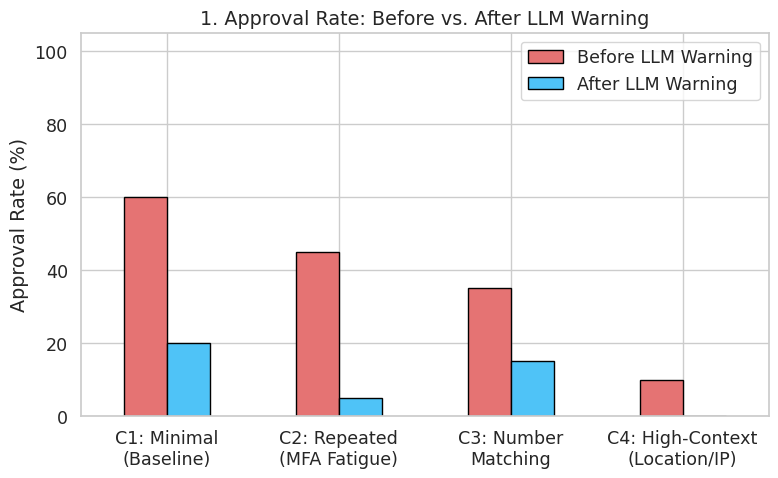

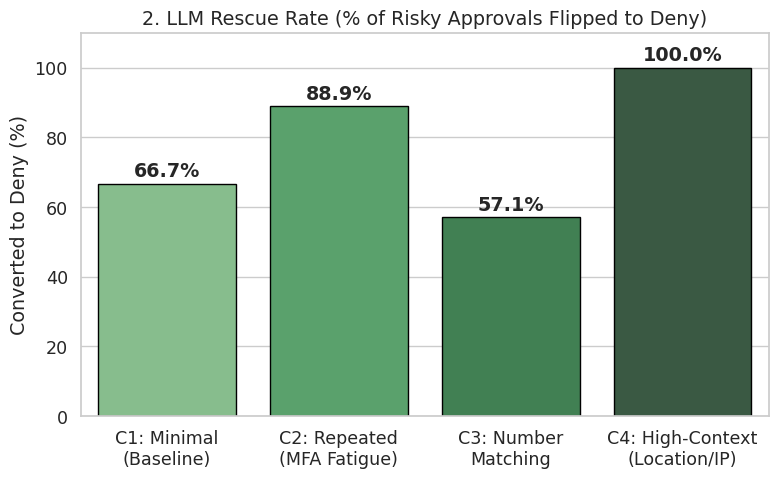

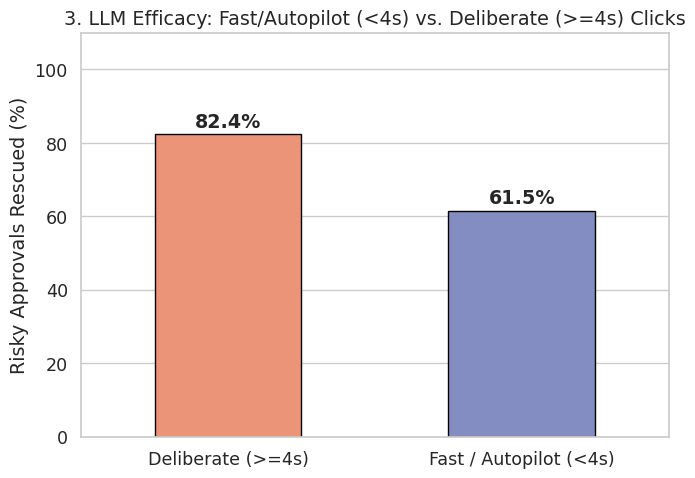

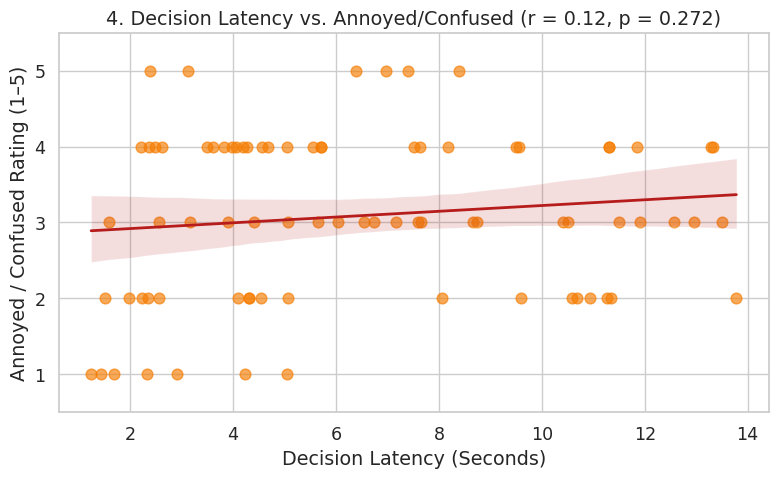

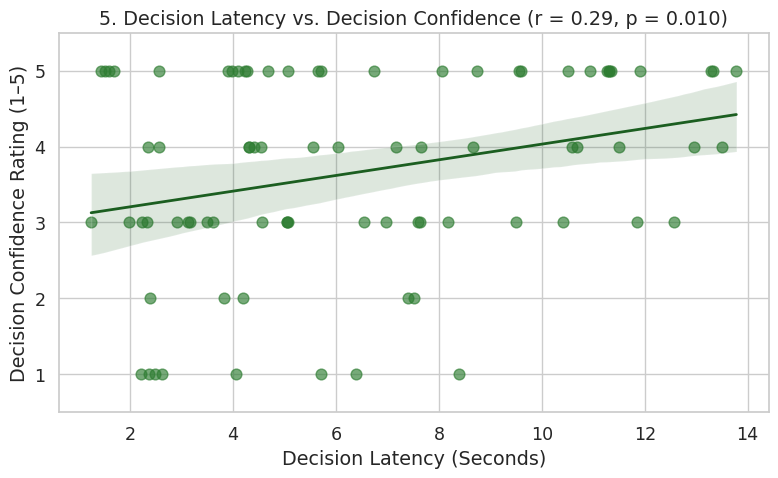

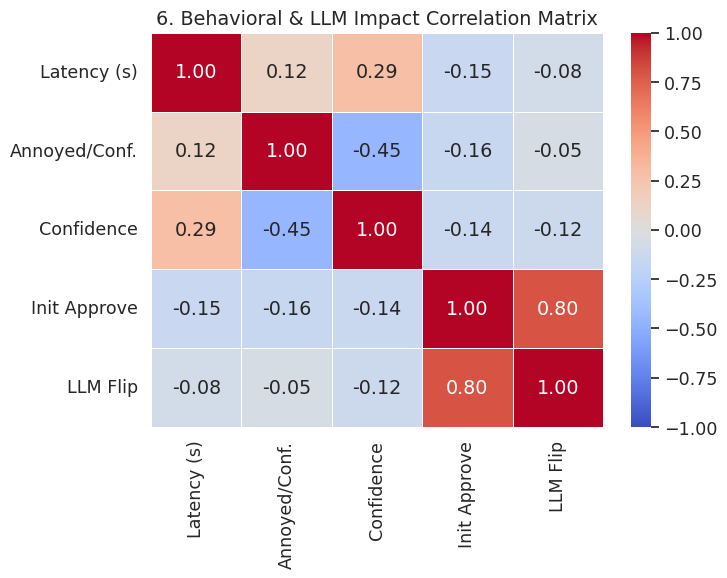

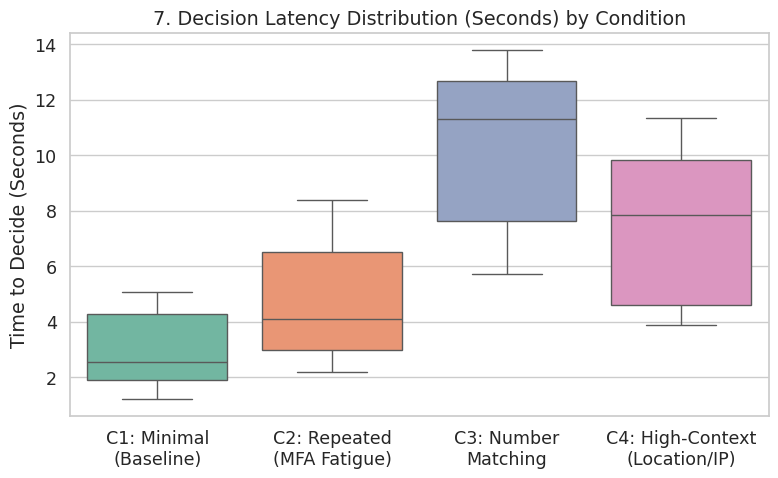

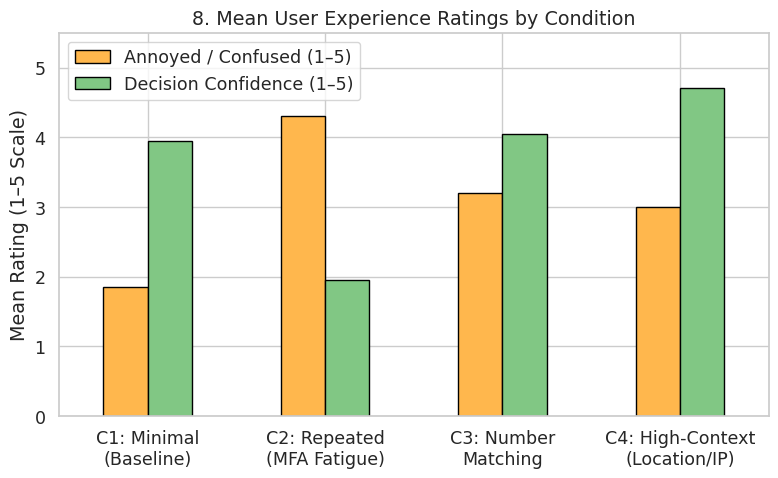

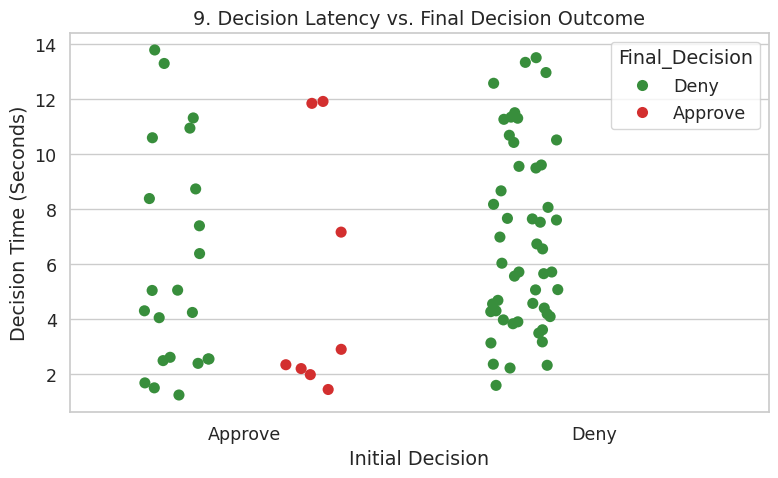

In [5]:
from google.colab import auth
import gspread
from google.auth import default
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

# 1. Authenticate & Load Google Sheet via URL
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_URL = 'https://docs.google.com/spreadsheets/d/1HBv67t7Dc-C6auwS5YrPK2ypU_ELI5pZnzUJqvXXZyY/edit?gid=0#gid=0'  # <-- Paste your full Google Sheet URL here
worksheet = gc.open_by_url(SHEET_URL).worksheet('Responses')

all_rows = worksheet.get_all_values()
header = all_rows.pop(0)
df = pd.DataFrame(all_rows, columns=header)

for col in ['Decision_Time_Sec', 'Annoyed_Confused', 'Confidence']:
    df[col] = pd.to_numeric(df[col])

# 2. Create Behavioral & LLM Impact Metrics
label_map = {
    'Condition 1': 'C1: Minimal\n(Baseline)',
    'Condition 2': 'C2: Repeated\n(MFA Fatigue)',
    'Condition 3': 'C3: Number\nMatching',
    'Condition 4': 'C4: High-Context\n(Location/IP)'
}
df['Cond_Label'] = df['Condition'].map(label_map)
order = list(label_map.values())

df['Init_Approve'] = (df['Initial_Decision'] == 'Approve').astype(int)
df['Final_Approve'] = (df['Final_Decision'] == 'Approve').astype(int)
df['Flipped_To_Deny'] = ((df['Initial_Decision'] == 'Approve') & (df['Final_Decision'] == 'Deny')).astype(int)
df['Flipped_To_Approve'] = ((df['Initial_Decision'] == 'Deny') & (df['Final_Decision'] == 'Approve')).astype(int)
df['Click_Speed_Group'] = np.where(df['Decision_Time_Sec'] < 4.0, 'Fast / Autopilot (<4s)', 'Deliberate (>=4s)')

risky_df = df[df['Initial_Decision'] == 'Approve'].copy()

# 3. Print Summary & Correlation Stats
llm_impact = df.groupby('Cond_Label').agg(
    Total_N=('Condition', 'count'),
    Initial_Approvals=('Init_Approve', 'sum'),
    Rescued_To_Deny=('Flipped_To_Deny', 'sum'),
    Accidental_To_Approve=('Flipped_To_Approve', 'sum'),
    Final_Approvals=('Final_Approve', 'sum'),
    Mean_Latency_Sec=('Decision_Time_Sec', lambda x: round(x.mean(), 2)),
    Mean_Annoyed=('Annoyed_Confused', lambda x: round(x.mean(), 2)),
    Mean_Confidence=('Confidence', lambda x: round(x.mean(), 2))
).reindex(order)
llm_impact['LLM_Rescue_Rate_Pct'] = (llm_impact['Rescued_To_Deny'] / llm_impact['Initial_Approvals'].replace(0, np.nan) * 100).round(1)

print("=== FULL STUDY & LLM IMPACT SUMMARY ===")
print(llm_impact.to_string(), "\n")

r_annoy, p_annoy = stats.pearsonr(df['Decision_Time_Sec'], df['Annoyed_Confused'])
r_conf, p_conf = stats.pearsonr(df['Decision_Time_Sec'], df['Confidence'])
r_ac, p_ac = stats.pearsonr(df['Annoyed_Confused'], df['Confidence'])

print("=== CORRELATIONS ===")
print(f"Latency vs. Annoyed/Confused : r = {r_annoy:.3f}, p = {p_annoy:.4f}")
print(f"Latency vs. Confidence       : r = {r_conf:.3f}, p = {p_conf:.4f}")
print(f"Annoyed/Confused vs. Conf.   : r = {r_ac:.3f}, p = {p_ac:.4f}\n")

ct = pd.crosstab(df['Initial_Decision'], df['Final_Decision'])
for val in ['Approve', 'Deny']:
    if val not in ct.index: ct.loc[val] = 0
    if val not in ct.columns: ct[val] = 0
ct = ct.loc[['Approve', 'Deny'], ['Approve', 'Deny']]
mc_res = mcnemar(ct, exact=True)
print(f"McNemar's Exact Test (Before vs. After LLM Warning): p = {mc_res.pvalue:.6f}\n")

sns.set_theme(style="whitegrid", font_scale=1.15)

# ==========================================
# PLOT 1: Before vs. After LLM Approval Rate
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
rate_df = df.groupby('Cond_Label')[['Init_Approve', 'Final_Approve']].mean().reindex(order) * 100
rate_df.columns = ['Before LLM Warning', 'After LLM Warning']
rate_df.plot(kind='bar', ax=ax, color=['#e57373', '#4fc3f7'], edgecolor='black')
ax.set_title('1. Approval Rate: Before vs. After LLM Warning')
ax.set_ylabel('Approval Rate (%)')
ax.set_xlabel('')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('plot1_approval_rates.png', dpi=300)
plt.show()

# ==========================================
# PLOT 2: LLM Rescue Rate by Condition
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
rescue_series = llm_impact['LLM_Rescue_Rate_Pct'].fillna(0)
sns.barplot(x=rescue_series.index, y=rescue_series.values, ax=ax, palette='Greens_d', hue=rescue_series.index, legend=False, edgecolor='black')
ax.set_title('2. LLM Rescue Rate (% of Risky Approvals Flipped to Deny)')
ax.set_ylabel('Converted to Deny (%)')
ax.set_xlabel('')
ax.set_ylim(0, 110)
for i, v in enumerate(rescue_series.values):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('plot2_llm_rescue_rate.png', dpi=300)
plt.show()

# ==========================================
# PLOT 3: LLM Efficacy: Autopilot vs. Deliberate Clicks
# ==========================================
fig, ax = plt.subplots(figsize=(7, 5))
speed_rescue = risky_df.groupby('Click_Speed_Group')['Flipped_To_Deny'].mean() * 100
sns.barplot(x=speed_rescue.index, y=speed_rescue.values, ax=ax, palette=['#ff8a65', '#7986cb'], hue=speed_rescue.index, legend=False, edgecolor='black', width=0.5)
ax.set_title('3. LLM Efficacy: Fast/Autopilot (<4s) vs. Deliberate (>=4s) Clicks')
ax.set_ylabel('Risky Approvals Rescued (%)')
ax.set_xlabel('')
ax.set_ylim(0, 110)
for i, v in enumerate(speed_rescue.values):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('plot3_autopilot_vs_deliberate.png', dpi=300)
plt.show()

# ==========================================
# PLOT 4: Latency vs. Annoyance/Confusion
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x='Decision_Time_Sec', y='Annoyed_Confused', ax=ax,
            scatter_kws={'alpha': 0.65, 's': 60, 'color': '#f57c00'}, line_kws={'color': '#b71c1c', 'linewidth': 2})
ax.set_title(f'4. Decision Latency vs. Annoyed/Confused (r = {r_annoy:.2f}, p = {p_annoy:.3f})')
ax.set_xlabel('Decision Latency (Seconds)')
ax.set_ylabel('Annoyed / Confused Rating (1–5)')
ax.set_ylim(0.5, 5.5)
plt.tight_layout()
plt.savefig('plot4_latency_vs_annoyed.png', dpi=300)
plt.show()

# ==========================================
# PLOT 5: Latency vs. Decision Confidence
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x='Decision_Time_Sec', y='Confidence', ax=ax,
            scatter_kws={'alpha': 0.65, 's': 60, 'color': '#2e7d32'}, line_kws={'color': '#1b5e20', 'linewidth': 2})
ax.set_title(f'5. Decision Latency vs. Decision Confidence (r = {r_conf:.2f}, p = {p_conf:.3f})')
ax.set_xlabel('Decision Latency (Seconds)')
ax.set_ylabel('Decision Confidence Rating (1–5)')
ax.set_ylim(0.5, 5.5)
plt.tight_layout()
plt.savefig('plot5_latency_vs_confidence.png', dpi=300)
plt.show()

# ==========================================
# PLOT 6: Behavioral & LLM Impact Correlation Heatmap
# ==========================================
fig, ax = plt.subplots(figsize=(7.5, 6))
corr_cols = df[['Decision_Time_Sec', 'Annoyed_Confused', 'Confidence', 'Init_Approve', 'Flipped_To_Deny']].copy()
corr_cols.columns = ['Latency (s)', 'Annoyed/Conf.', 'Confidence', 'Init Approve', 'LLM Flip']
sns.heatmap(corr_cols.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('6. Behavioral & LLM Impact Correlation Matrix')
plt.tight_layout()
plt.savefig('plot6_correlation_heatmap.png', dpi=300)
plt.show()

# ==========================================
# PLOT 7: Decision Latency Distribution by Condition (Boxplot)
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='Cond_Label', y='Decision_Time_Sec', order=order, ax=ax, palette='Set2', hue='Cond_Label', legend=False)
ax.set_title('7. Decision Latency Distribution (Seconds) by Condition')
ax.set_ylabel('Time to Decide (Seconds)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig('plot7_latency_boxplot.png', dpi=300)
plt.show()

# ==========================================
# PLOT 8: Mean User Experience Ratings by Condition
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
rating_df = df.groupby('Cond_Label')[['Annoyed_Confused', 'Confidence']].mean().reindex(order)
rating_df.columns = ['Annoyed / Confused (1–5)', 'Decision Confidence (1–5)']
rating_df.plot(kind='bar', ax=ax, color=['#ffb74d', '#81c784'], edgecolor='black')
ax.set_title('8. Mean User Experience Ratings by Condition')
ax.set_ylabel('Mean Rating (1–5 Scale)')
ax.set_xlabel('')
ax.set_ylim(0, 5.5)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('plot8_ux_ratings_by_condition.png', dpi=300)
plt.show()

# ==========================================
# PLOT 9: Click Speed vs. Final Decision Outcome
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(
    data=df,
    x='Initial_Decision',
    y='Decision_Time_Sec',
    hue='Final_Decision',
    dodge=True,
    jitter=0.2,
    size=8,
    palette={'Approve': '#d32f2f', 'Deny': '#388e3c'},
    ax=ax
)
ax.set_title('9. Decision Latency vs. Final Decision Outcome')
ax.set_ylabel('Decision Time (Seconds)')
ax.set_xlabel('Initial Decision')
plt.tight_layout()
plt.savefig('plot9_latency_vs_outcome.png', dpi=300)
plt.show()
